# College Placement Analysis

Exploratory analysis of MBA campus placement records using Pandas, Matplotlib and
Seaborn. The workflow is **load -> inspect -> clean -> analyse -> visualise**.

- **Input:** `data/placement_raw.csv` (215 records, 15 columns)
- **Output:** `data/cleaned_placement.csv` plus four PNG charts in `images/`

All figures quoted below are computed by the code in this notebook, not typed by hand.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

DATA_DIR = Path("data")
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

print("pandas ", pd.__version__)
print("seaborn", sns.__version__)

pandas  3.0.5
seaborn 0.13.2


## 1. Load the dataset

The raw file is read straight into a DataFrame. Salary is blank for students who were
not placed, which is expected rather than a data quality fault.

In [2]:
df = pd.read_csv(DATA_DIR / "placement_raw.csv")

print("Shape:", df.shape)
df.head()

Shape: (215, 15)


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


## 2. Inspect the data

Before cleaning, check size, dtypes, missing values and duplicates. This tells us
whether cleaning is needed at all.

In [3]:
print("--- dtypes ---")
print(df.dtypes)

print("\n--- missing values ---")
print(df.isna().sum()[df.isna().sum() > 0])

print("\n--- duplicate rows ---", int(df.duplicated().sum()))

print("\n--- salary dtype ---", df["salary"].dtype)
df.describe()

--- dtypes ---
sl_no               int64
gender                str
ssc_p             float64
ssc_b                 str
hsc_p             float64
hsc_b                 str
hsc_s                 str
degree_p          float64
degree_t              str
workex                str
etest_p           float64
specialisation        str
mba_p             float64
status                str
salary            float64
dtype: object

--- missing values ---
salary    67
dtype: int64

--- duplicate rows --- 0

--- salary dtype --- float64


,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,148.000000
mean,108.000000,67.303395,66.333163,66.370186,72.100558,62.278186,288655.405405
std,62.209324,10.827205,10.897509,7.358743,13.275956,5.833385,93457.452420
min,1.000000,40.890000,37.000000,50.000000,50.000000,51.210000,200000.000000
25%,54.500000,60.600000,60.900000,61.000000,60.000000,57.945000,240000.000000
50%,108.000000,67.000000,65.000000,66.000000,71.000000,62.000000,265000.000000
75%,161.500000,75.700000,73.000000,72.000000,83.500000,66.255000,300000.000000
max,215.000000,89.400000,97.700000,91.000000,98.000000,77.890000,940000.000000


## 3. Clean the data

Three steps: drop duplicate rows, coerce `salary` to numeric in case any entry is
formatted as text, and write the result back to disk.

On this dataset `drop_duplicates()` and `to_numeric()` are no-ops — the checks above
confirmed 0 duplicates and a numeric salary column. They are kept because the notebook
is meant to re-run against a revised file.

In [4]:
df = df.drop_duplicates()
df["salary"] = pd.to_numeric(df["salary"], errors="coerce")

df.to_csv(DATA_DIR / "cleaned_placement.csv", index=False)

print("Rows after cleaning:", len(df))
print("Rows written to data/cleaned_placement.csv")

Rows after cleaning: 215
Rows written to data/cleaned_placement.csv


## 4. Placement rate

Overall split between placed and not placed students.

In [5]:
placement_rate = df["status"].value_counts(normalize=True) * 100
placement_rate.round(2)

print(f"Overall placement rate: {placement_rate['Placed']:.1f}%")

Overall placement rate: 68.8%


## 5. Effect of work experience

Students with prior work experience place at a far higher rate than those without.

In [6]:
by_workex = pd.crosstab(df["workex"], df["status"], normalize="index") * 100
by_workex.round(1)

status,Not Placed,Placed
workex,,
No,40.4,59.6
Yes,13.5,86.5


## 6. Placement rate by HSC stream

In [7]:
by_stream = pd.crosstab(df["hsc_s"], df["status"], normalize="index") * 100
by_stream.round(1)

status,Not Placed,Placed
hsc_s,,
Arts,45.5,54.5
Commerce,30.1,69.9
Science,30.8,69.2


## 7. Salary statistics (placed students only)

Salaries are only defined for students who received an offer, so all salary analysis is
restricted to the placed subset.

In [8]:
placed = df[df["status"] == "Placed"].copy()

salary_stats = placed["salary"].describe()
salary_stats.round(2)

print(f"Mean   : {salary_stats['mean']:,.2f}")
print(f"Median : {salary_stats['50%']:,.0f}")
print(f"Std dev: {salary_stats['std']:,.2f}")
print(f"Total salary spend: {placed['salary'].sum():,.0f}")

Mean   : 288,655.41
Median : 265,000
Std dev: 93,457.45
Total salary spend: 42,721,000


## 8. Visualisation

Four charts are produced and saved to `images/`.

### 8.1 Placed vs Not Placed

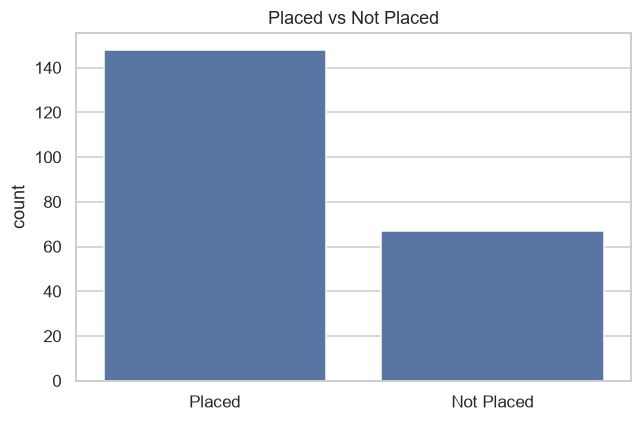

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="status", data=df, ax=ax)
ax.set_title("Placed vs Not Placed")
ax.set_xlabel("")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "chart1_placed_vs_not_placed.png", bbox_inches="tight")
plt.show()

### 8.2 Salary distribution of placed students

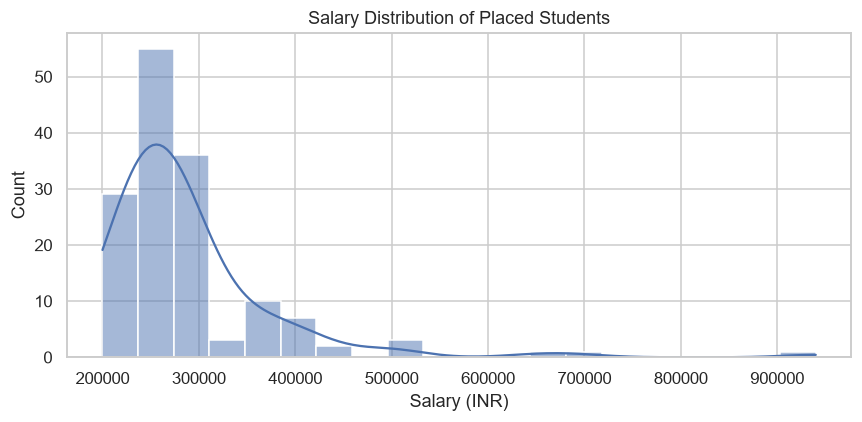

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(placed["salary"], kde=True, bins=20, ax=ax)
ax.set_title("Salary Distribution of Placed Students")
ax.set_xlabel("Salary (INR)")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "chart2_salary_distribution.png", bbox_inches="tight")
plt.show()

### 8.3 Salary by HSC stream

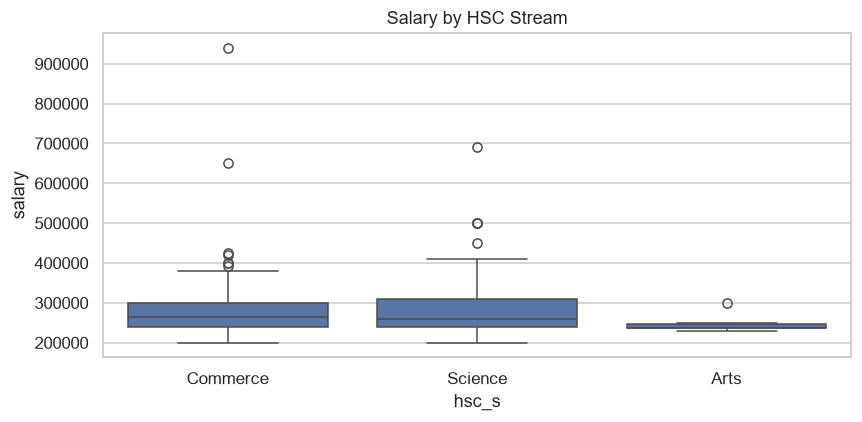

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x="hsc_s", y="salary", data=placed, ax=ax)
ax.set_title("Salary by HSC Stream")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "chart3_salary_by_stream.png", bbox_inches="tight")
plt.show()

### 8.4 Degree percentage vs salary

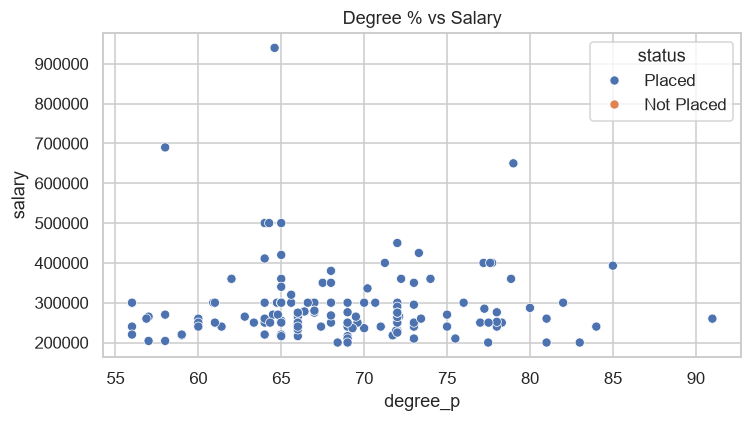

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(x="degree_p", y="salary", hue="status", data=df, ax=ax)
ax.set_title("Degree % vs Salary")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "chart4_degree_vs_salary.png", bbox_inches="tight")
plt.show()

## 9. Key findings

Every figure below is printed by this cell, so the numbers and the code cannot drift
apart.

In [13]:
overall = df["status"].value_counts(normalize=True)["Placed"] * 100
workex = pd.crosstab(df["workex"], df["status"], normalize="index")["Placed"] * 100
stream = pd.crosstab(df["hsc_s"], df["status"], normalize="index")["Placed"] * 100

print(f"Records analysed      : {len(df)}")
print(f"Overall placement rate: {overall:.1f}%")
print(f"With work experience  : {workex['Yes']:.1f}%")
print(f"Without work experience: {workex['No']:.1f}%")
print()
print("Placement rate by stream:")
for name, value in stream.sort_values(ascending=False).items():
    print(f"  {name:<10} {value:.1f}%")
print()
print(f"Mean salary           : {placed['salary'].mean():,.2f}")
print(f"Median salary         : {placed['salary'].median():,.0f}")
print(f"Std deviation         : {placed['salary'].std():,.2f}")
print(f"Highest offer         : {placed['salary'].max():,.0f}")
print(f"Total salary spend    : {placed['salary'].sum():,.0f}")

Records analysed      : 215
Overall placement rate: 68.8%
With work experience  : 86.5%
Without work experience: 59.6%

Placement rate by stream:
  Commerce   69.9%
  Science    69.2%
  Arts       54.5%

Mean salary           : 288,655.41
Median salary         : 265,000
Std deviation         : 93,457.45
Highest offer         : 940,000
Total salary spend    : 42,721,000
